# 02 · Modelos: quanto tempo a entrega vai levar

Primeiro a previsão **pontual** (a mediana: metade das entregas leva menos, metade leva mais). O prazo que aparece no app vem no notebook 03.

## Features, sem vazamento

Tudo o que usa resultados de entregas passadas considera **só as entregas que já tinham terminado** no momento do pedido (`actual_delivery_time < created_at`). É o que a plataforma saberia de verdade:

| Grupo | Features |
|---|---|
| Pedido | itens, itens distintos, subtotal, preço mínimo/máximo |
| Loja/mercado | mercado, categoria, protocolo |
| Horário | hora (UTC), dia da semana |
| Oferta x demanda | entregadores online/ocupados/livres, pedidos na fila, fila por entregador, ocupação |
| Estimativas da plataforma | envio pra loja, deslocamento |
| Histórico da loja | nº de entregas já concluídas e tempo médio (suavizado pra lojas novas) |
| Mercado em tempo real | nº de entregas concluídas na última hora e tempo médio delas |

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

# paleta categórica validada (daltonismo) + estilo discreto
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3b3b38",
    "xtick.color": "#5c5c58", "ytick.color": "#5c5c58",
    "lines.linewidth": 2, "lines.markersize": 7, "figure.dpi": 110,
})

In [2]:
from eta import load, build
from eta.models import MedianaGlobal, RegraPlataforma, LGBQuantil

df = load()
media_treino = df.loc[df["periodo"] == "treino", "minutos"].mean()
X = build(df, media_treino)
y = df["minutos"].to_numpy()
P = {p: (df["periodo"] == p).to_numpy() for p in ["treino", "validacao", "calibracao", "teste"]}
print(X.shape)
X.head()

(197280, 23)


,itens,itens_distintos,subtotal,preco_min,preco_max,market_id,order_protocol,categoria,hora,dia_semana,...,entregadores_livres,fila_por_entregador,ocupacao,est_envio_loja,est_deslocamento,loja_n,loja_media,mercado_1h_n,mercado_1h_media,loja_media_menos_deslocamento
0,2,2,10.58,2.19,7.99,1,4,dessert,15,2,...,1.0,0.500000,0.500000,4.183333,7.716667,0.0,47.799557,0.0,NaN,40.082890
1,2,2,6.90,1.95,2.55,3,4,cafe,15,2,...,2.0,0.500000,0.000000,4.183333,7.633333,0.0,47.799557,0.0,NaN,40.166224
2,3,3,18.67,4.49,5.29,1,4,desconhecida,15,2,...,3.0,0.250000,0.250000,4.183333,4.733333,0.0,47.799557,0.0,NaN,43.066224
3,3,3,9.55,2.45,3.45,1,4,cafe,15,2,...,1.0,0.666667,0.666667,4.183333,6.283333,0.0,47.799557,0.0,NaN,41.516224
4,3,1,8.25,1.25,1.25,1,3,chinese,15,2,...,0.0,NaN,NaN,4.183333,8.900000,0.0,47.799557,0.0,NaN,38.899557


## Comparação

- **Mediana global:** sempre o mesmo número.
- **Regra:** o que um sistema sem ML faria. Soma as estimativas que a plataforma já calcula (envio + deslocamento) com um tempo de preparo mediano.
- **LightGBM (mediana):** regressão quantílica no quantil 0,5, com early stopping na validação.

In [3]:
modelos = [MedianaGlobal(), RegraPlataforma(), LGBQuantil(0.5)]
for m in modelos[:2]:
    m.fit(X[P["treino"]], y[P["treino"]])
modelos[2].fit(X[P["treino"]], y[P["treino"]], X[P["validacao"]], y[P["validacao"]])

linhas = []
for m in modelos:
    for per in ["validacao", "teste"]:
        e = y[P[per]] - m.predict(X[P[per]])
        linhas.append({"modelo": m.nome, "periodo": per, "MAE (min)": np.mean(np.abs(e)),
                       "viés (min)": np.mean(e), "erro > 15 min (%)": np.mean(np.abs(e) > 15) * 100})
res = pd.DataFrame(linhas).pivot(index="modelo", columns="periodo").round(2)
res.loc[[m.nome for m in modelos]]

MAE (min)           viés (min)           erro > 15 min (%)          
periodo                                            teste validacao      teste validacao             teste validacao
modelo                                                                                                             
Mediana global                                     13.46     13.01       4.33      2.06             32.76     32.18
Regra (envio + deslocamento + preparo mediano)     12.94     12.47       4.27      2.07             30.23     29.41
LightGBM (mediana)                                 10.29     10.07       1.86      1.01             20.97     19.81

In [4]:
mae_regra = np.mean(np.abs(y[P["teste"]] - modelos[1].predict(X[P["teste"]])))
mae_lgb = np.mean(np.abs(y[P["teste"]] - modelos[2].predict(X[P["teste"]])))
print(f"No teste, o LightGBM erra em média {mae_lgb:.1f} min, contra {mae_regra:.1f} min da regra ({(1 - mae_lgb / mae_regra) * 100:.0f}% a menos)")

No teste, o LightGBM erra em média 10.3 min, contra 12.9 min da regra (20% a menos)


O **viés positivo** no teste (as entregas demoraram mais do que o previsto) vem da semana atípica (notebook 01). Ele é bem menor no LightGBM, que enxerga a fila e o tempo médio da última hora e se adapta. Os baselines não têm como saber que o dia está mais lento.

## O que o modelo usa

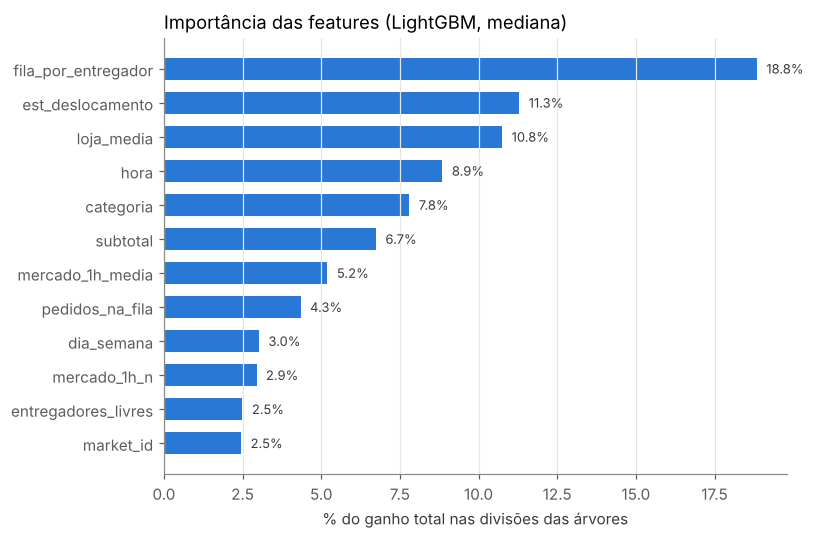

In [5]:
lgb_mediana = modelos[2]
imp = pd.Series(lgb_mediana.booster_.feature_importance("gain"), index=X.columns)
imp = (imp / imp.sum() * 100).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(imp.index, imp.values, color=CORES[0], height=0.65)
for i, v in enumerate(imp.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8.5, color="#3b3b38")
ax.grid(axis="y", visible=False); ax.set_xlabel("% do ganho total nas divisões das árvores")
ax.set_title("Importância das features (LightGBM, mediana)", loc="left")
plt.tight_layout(); plt.savefig("../results/importancia_features.png", dpi=150); plt.show()

## Ablação: quanto cada grupo de features contribui

Treina o mesmo modelo sem um grupo de cada vez. A diferença de MAE no teste mostra quanto aquele grupo agrega além dos outros.

In [6]:
grupos = {
    "oferta x demanda": ["entregadores_online", "entregadores_ocupados", "pedidos_na_fila", "entregadores_livres", "fila_por_entregador", "ocupacao"],
    "histórico da loja": ["loja_n", "loja_media", "loja_media_menos_deslocamento"],
    "mercado na última hora": ["mercado_1h_n", "mercado_1h_media"],
    "estimativas da plataforma": ["est_envio_loja", "est_deslocamento", "loja_media_menos_deslocamento"],
}
abl = [{"sem": "(modelo completo)", "MAE teste": mae_lgb}]
for nome, cols in grupos.items():
    Xs = X.drop(columns=cols)
    m = LGBQuantil(0.5).fit(Xs[P["treino"]], y[P["treino"]], Xs[P["validacao"]], y[P["validacao"]])
    abl.append({"sem": nome, "MAE teste": np.mean(np.abs(y[P["teste"]] - m.predict(Xs[P["teste"]])))})
abl = pd.DataFrame(abl).set_index("sem")
abl["piora (min)"] = abl["MAE teste"] - mae_lgb
abl.round(2)

,MAE teste,piora (min)
sem,,
(modelo completo),10.29,0.00
oferta x demanda,10.83,0.54
histórico da loja,10.62,0.33
mercado na última hora,10.34,0.05
estimativas da plataforma,10.74,0.44


## Hiperparâmetros

Testei 24 combinações de `num_leaves` (31–255), `min_child_samples` (20–200) e `feature_fraction` (0,6–0,8), escolhendo pela validação. O MAE de validação variou só entre 10,05 e 10,10 minutos, então os parâmetros padrão (`num_leaves=63`, `min_child_samples=50`, `feature_fraction=0,8`) foram mantidos. O ganho está nas features, não no ajuste fino.